# Análisis exploratorio de datos bursátiles

Este cuaderno realiza un análisis exploratorio de un conjunto de datos bursátiles formado por 26 empresas. Para cada *ticker* se dispone de cinco variables: precio de apertura (`open`), máximo diario (`high`), mínimo diario (`low`), precio de cierre (`close`) y volumen negociado (`volume`).

Las columnas presentan una estructura jerárquica de dos niveles: el primero identifica el *ticker* y el segundo la variable observada. Todas las variables son de tipo `float`.

El análisis se centra en describir la estructura de los datos, comprobar su consistencia, estudiar la evolución de los precios y del volumen, calcular rentabilidades, analizar la volatilidad, cuantificar las relaciones entre empresas y detectar observaciones extremas. Los resultados obtenidos tienen carácter descriptivo y se refieren únicamente al periodo contenido en el conjunto de datos.

## 1. Importación de bibliotecas y configuración

Se cargan las bibliotecas necesarias y se definen los *tickers* y atributos esperados. La configuración gráfica se mantiene sencilla para facilitar la lectura de las figuras.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import os
import pyarrow.parquet as pq

df = pq.read_table(os.path.join('..', 'DATOS', 'TRANSFORMADOS', 'df_diario.parquet')).to_pandas()

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

paleta_bbva = {
    # --- PALETA PRIMARIA (CORE) ---
    "azul_logotipo": "#14549C",
    "azul_oscuro_digital": "#06257C",
    "azul_medio_electric": "#00539B",
    "azul_celeste_aqua": "#00B1E1",
    "blanco": "#FFFFFF",
    
    # --- INTERFAZ, FONDOS Y TEXTOS (UI) ---
    "azul_profundo_texto": "#070E46",
    "gris_bordes": "#DCDCDC",
    "gris_divisores": "#EAEAEA",
    "gris_fondo_canvas": "#F4F4F4",
    
    # --- ACENTOS, ALERTAS Y SOSTENIBILIDAD ---
    "verde_sostenibilidad": "#068B29",
    "verde_claro": "#A6DD2B",
    "naranja_alerta": "#F37022"
}

# Colores principales para gráficos
colores_bbva = [
    paleta_bbva["azul_logotipo"],
    paleta_bbva["azul_oscuro_digital"],
    paleta_bbva["azul_medio_electric"],
    paleta_bbva["azul_celeste_aqua"],
    paleta_bbva["verde_sostenibilidad"],
    paleta_bbva["verde_claro"],
    paleta_bbva["naranja_alerta"]
]

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.size"] = 10

plt.rcParams["axes.facecolor"] = paleta_bbva["blanco"]
plt.rcParams["figure.facecolor"] = paleta_bbva["blanco"]
plt.rcParams["axes.edgecolor"] = paleta_bbva["gris_bordes"]
plt.rcParams["axes.labelcolor"] = paleta_bbva["azul_profundo_texto"]
plt.rcParams["text.color"] = paleta_bbva["azul_profundo_texto"]
plt.rcParams["xtick.color"] = paleta_bbva["azul_profundo_texto"]
plt.rcParams["ytick.color"] = paleta_bbva["azul_profundo_texto"]

tickers = [
    'AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW',
    'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK',
    'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V'
]

atributos = ['close', 'high', 'low', 'open', 'volume']

## 2. Estructura general del conjunto de datos

La primera revisión permite conocer el número de observaciones, el número de columnas, el intervalo temporal disponible y la organización interna del `DataFrame`. También se comprueba que las columnas correspondan a un `MultiIndex` con los niveles `Ticker` y `Atributo`.

In [2]:
print(f"Número de filas: {df.shape[0]}")
print(f"Número de columnas: {df.shape[1]}")
print(f"Tipo del índice: {type(df.index).__name__}")
print(f"Tipo de las columnas: {type(df.columns).__name__}")

print("\nPrimeras observaciones:")
display(df.head())

print("\nÚltimas observaciones:")
display(df.tail())

Número de filas: 1760
Número de columnas: 130
Tipo del índice: DatetimeIndex
Tipo de las columnas: MultiIndex

Primeras observaciones:


Ticker        AAPL                                    AMGN                    \
Atributo     close    high     low    open volume    close     high      low   
date                                                                           
2018-06-06 45.8908 45.8908 45.4059 45.8033 0.0000 115.6554 116.0334 113.9667   
2018-06-07 45.7725 45.9286 45.5088 45.9274 0.0000 115.4978 115.9704 115.0001   
2018-06-08 45.3018 45.4165 44.8985 45.1764 0.0000 116.1279 116.9786 115.6869   
2018-06-11 45.2190 45.4106 44.9990 45.2627 0.0000 116.3233 116.4556 115.2647   
2018-06-12 45.4934 45.5596 45.2225 45.2722 0.0000 116.6131 116.6446 115.5672   

Ticker                                 AXP                          \
Atributo       open         volume   close    high     low    open   
date                                                                 
2018-06-06 114.6850 2,213,100.0000 82.2149 82.2394 81.0750 81.4251   
2018-06-07 115.6050 2,729,600.0000 82.6302 83.3712 82.1498 82.5976   
2018-06-08 115.8696 2,865,000.0000 82.2393 82.4836 81.0912 82.4755   
2018-06-11 116.0271 2,409,400.0000 82.4022 82.7849 82.0683 82.3859   
2018-06-12 116.1090 2,045,300.0000 82.0195 82.6465 81.6205 82.6465   

Ticker                          BA                                            \
Atributo           volume    close     high      low     open         volume   
date                                                                           
2018-06-06 2,872,700.0000 344.1973 344.2344 334.4057 335.7674 4,488,400.0000   
2018-06-07 4,245,700.0000 341.3905 346.9023 339.0931 344.6049 4,517,800.0000   
2018-06-08 3,580,500.0000 342.2890 344.0677 338.5465 341.0292 3,292,900.0000   
2018-06-11 3,453,000.0000 343.6230 345.8370 341.6406 343.6786 2,468,500.0000   
2018-06-12 2,426,100.0000 343.3265 345.2812 340.8902 343.9009 2,440,400.0000   

Ticker          CAT                                                CRM  \
Atributo      close     high      low     open         volume    close   
date                                                                     
2018-06-06 112.5292 112.5508 110.0127 110.4729 3,689,300.0000 132.0645   
2018-06-07 112.3710 113.5502 111.8246 112.9606 3,149,100.0000 129.4924   
2018-06-08 111.6736 112.6299 111.4723 112.2991 3,254,100.0000 130.0965   
2018-06-11 133.3920 133.6267 132.0481 132.3553         0.0000 130.5348   
2018-06-12 135.3589 135.7685 133.5670 133.7035         0.0000 132.7562   

Ticker                                                  CSCO                  \
Atributo       high      low     open         volume   close    high     low   
date                                                                           
2018-06-06 132.2204 130.6713 130.8759 4,766,900.0000 28.2285 28.2604 27.8458   
2018-06-07 132.2594 127.3685 132.0645 6,564,100.0000 27.8395 28.3114 27.6481   
2018-06-08 130.2426 127.4562 128.3135 3,486,600.0000 27.7310 27.8905 27.6226   
2018-06-11 131.2071 129.8333 130.4374 3,443,100.0000 27.8650 28.0117 27.7055   
2018-06-12 133.9644 131.1876 131.4897 5,319,900.0000 28.0244 28.0308 27.7247   

Ticker                                 CVX                          \
Atributo      open          volume   close    high     low    open   
date                                                                 
2018-06-06 27.9096 17,730,200.0000 63.8461 64.0065 63.1630 63.7115   
2018-06-07 28.2158 19,722,000.0000 65.6986 66.2265 64.3791 64.4463   
2018-06-08 27.7565 18,812,400.0000 65.4295 65.9160 65.0363 65.7814   
2018-06-11 27.8203 15,069,000.0000 66.0091 66.3351 65.1294 65.6003   
2018-06-12 27.8586 17,564,900.0000 65.7607 66.4334 65.3726 66.0505   

Ticker                        DIS                                         \
Atributo           volume   close    high     low    open         volume   
date                                                                       
2018-06-06 6,213,400.0000 92.3091 92.3362 90.3616 90.6333 7,833,000.0000   
2018-06-07 8,607,200.0000 92.8163 93.2601 92.2185 92.3091 


Últimas observaciones:


Ticker         AAPL                                                AMGN  \
Atributo      close     high      low     open          volume    close   
date                                                                      
2025-05-30 199.8840 200.9886 195.8335 198.4111 70,819,900.0000 278.1452   
2025-06-02 200.7299 201.1578 199.1575 199.3167 35,423,300.0000 278.4251   
2025-06-03 202.2923 202.7899 199.9934 200.3815 46,381,600.0000 279.4868   
2025-06-04 201.8445 205.2480 201.1279 201.9340 43,604,000.0000 277.0160   
2025-06-05 199.6650 203.7652 199.1873 202.5212 55,126,100.0000 277.1028   

Ticker                                                    AXP           \
Atributo       high      low     open         volume    close     high   
date                                                                     
2025-05-30 278.7533 271.2538 272.7691 5,439,200.0000 290.2053 291.8831   
2025-06-02 279.3710 274.8539 275.6937 2,394,000.0000 291.4686 291.8831   
2025-06-03 281.6006 273.1842 275.5778 2,320,400.0000 293.5017 294.3504   
2025-06-04 283.0001 276.9001 280.0852 2,338,300.0000 292.0608 294.7452   
2025-06-05 281.2144 275.0662 276.3596 2,522,400.0000 292.0903 294.5971   

Ticker                                            BA                    \
Atributo        low     open         volume    close     high      low   
date                                                                     
2025-05-30 287.8170 291.1133 5,251,700.0000 207.3200 207.7000 204.3500   
2025-06-02 286.5340 288.5276 1,751,200.0000 211.4700 212.3400 207.9000   
2025-06-03 288.8236 291.3403 2,202,400.0000 213.4300 215.8000 211.7700   
2025-06-04 291.9325 293.9162 1,842,100.0000 211.9800 214.9900 211.0300   
2025-06-05 290.2942 292.6233 1,696,900.0000 209.0200 212.9900 208.2200   

Ticker                                  CAT                             \
Atributo       open         volume    close     high      low     open   
date                                                                     
2025-05-30 206.7700 7,485,100.0000 343.6662 348.8109 342.6689 347.4185   
2025-06-02 210.9800 7,561,800.0000 340.3483 342.1257 335.2431 342.1257   
2025-06-03 212.0000 8,106,100.0000 345.0190 346.4410 340.5952 341.6616   
2025-06-04 214.7700 5,705,300.0000 344.9499 347.3198 344.9499 345.9077   
2025-06-05 212.5000 4,733,800.0000 344.5845 347.1025 341.5135 346.5989   

Ticker                         CRM                                             \
Atributo           volume    close     high      low     open          volume   
date                                                                            
2025-05-30 4,867,100.0000 262.2648 266.5837 257.6495 264.9431 12,388,500.0000   
2025-06-02 2,552,700.0000 258.5587 260.7033 256.1077 260.0312  9,213,500.0000   
2025-06-03 2,614,300.0000 261.3753 261.6521 258.3017 258.9342  7,838,500.0000   
2025-06-04 1,616,300.0000 260.0906 262.3933 258.5587 261.0986  7,372,500.0000   
2025-06-05 1,753,300.0000 264.0141 265.6052 260.5551 260.6242  8,642,900.0000   

Ticker        CSCO                                              CVX           \
Atributo     close    high     low    open          volume    close     high   
date                                                                           
2025-05-30 61.3920 61.5283 60.6713 61.2751 25,829,000.0000 130.0696 130.7833   
2025-06-02 62.1808 62.2100 61.0706 61.0901 15,816,000.0000 131.1543 131.9631   
2025-06-03 62.6775 62.7748 62.0542 62.1321 15,156,900.0000 132.7814 133.7710   
2025-06-04 62.7067 63.1936 62.6677 62.9696 14,770,900.0000 130.7071 133.8090   
2025-06-05 62.9307 63.2131 62.5995 62.7943 17,025,200.0000 130.2599 131.5825   

Ticker                                            DIS                    \
Atributo        low     open          volume    close     high      low   
date                                                                      
2025-05-30 128.6519 130.2409 12,858,900.0000 110.9534 111.2577 109.3142   
2025-06-02 129.8127 131.7728  

In [3]:
if not isinstance(df.columns, pd.MultiIndex) or df.columns.nlevels != 2:
    raise ValueError(
        "Las columnas deben ser un MultiIndex de dos niveles: (Ticker, Atributo)."
    )

df.columns = df.columns.set_names(["Ticker", "Atributo"])

tickers_presentes = df.columns.get_level_values("Ticker").unique().tolist()
atributos_presentes = df.columns.get_level_values("Atributo").unique().tolist()

print("Tickers presentes:")
print(tickers_presentes)

print("\nAtributos presentes:")
print(atributos_presentes)

Tickers presentes:
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']

Atributos presentes:
['close', 'high', 'low', 'open', 'volume']


In [4]:
tipos = df.dtypes.rename("dtype").reset_index()
display(tipos)

print("\nFrecuencia de tipos de datos:")
display(tipos["dtype"].value_counts())

,Ticker,Atributo,dtype
0,AAPL,close,float64
1,AAPL,high,float64
2,AAPL,low,float64
3,AAPL,open,float64
4,AAPL,volume,float64
...,...,...,...
125,V,close,float64
126,V,high,float64
127,V,low,float64
128,V,open,float64



Frecuencia de tipos de datos:


dtype
float64    130
Name: count, dtype: int64

## 3. Revisión del índice temporal

En una serie bursátil el orden cronológico es necesario para calcular variaciones, rentabilidades y ventanas móviles. Se comprueba si el índice está ordenado y si contiene fechas duplicadas. Cuando el índice no está ordenado, se ordena de forma creciente antes de continuar.

In [5]:
print("Índice ordenado de forma creciente:", df.index.is_monotonic_increasing)
print("Valores duplicados en el índice:", int(df.index.duplicated().sum()))

if not df.index.is_monotonic_increasing:
    df = df.sort_index()
    print("El DataFrame se ha ordenado cronológicamente.")

print("\nPrimera fecha:", df.index.min())
print("Última fecha:", df.index.max())
print("Número de observaciones temporales:", len(df))

Índice ordenado de forma creciente: True
Valores duplicados en el índice: 0

Primera fecha: 2018-06-06 00:00:00
Última fecha: 2025-06-05 00:00:00
Número de observaciones temporales: 1760


## 4. Comprobaciones de calidad

Se revisan valores ausentes, valores infinitos y filas duplicadas. Aunque el conjunto de datos haya sido limpiado previamente, estas comprobaciones permiten documentar su estado antes de comenzar el análisis.

In [6]:
nulos = df.isna().sum()

resumen_nulos = pd.DataFrame({
    "n_nulos": nulos,
    "porcentaje_nulos": 100 * nulos / len(df)
})

print("Número total de valores ausentes:", int(nulos.sum()))
display(resumen_nulos[resumen_nulos["n_nulos"] > 0])

print("\nNúmero de filas completamente duplicadas:", int(df.duplicated().sum()))
print("Número de valores infinitos:", int(np.isinf(df.to_numpy()).sum()))

Número total de valores ausentes: 896


,,n_nulos,porcentaje_nulos
Ticker,Atributo,,
AAPL,close,4,0.2273
AMGN,close,4,0.2273
AXP,close,4,0.2273
BA,close,4,0.2273
CAT,close,4,0.2273
CRM,close,4,0.2273
CSCO,close,4,0.2273
CVX,close,4,0.2273
DIS,close,4,0.2273



Número de filas completamente duplicadas: 0
Número de valores infinitos: 0


## 5. Separación de las variables principales

Para simplificar los cálculos posteriores se extraen cinco `DataFrame`, uno por variable. Cada columna pasa a representar una empresa.

In [7]:
close = df.xs("close", axis=1, level="Atributo").copy()
high = df.xs("high", axis=1, level="Atributo").copy()
low = df.xs("low", axis=1, level="Atributo").copy()
open_ = df.xs("open", axis=1, level="Atributo").copy()
volume = df.xs("volume", axis=1, level="Atributo").copy()

orden = [ticker for ticker in tickers if ticker in close.columns]

close = close[orden]
high = high[orden]
low = low[orden]
open_ = open_[orden]
volume = volume[orden]

print("Dimensiones de cada bloque:")
print("close :", close.shape)
print("high  :", high.shape)
print("low   :", low.shape)
print("open  :", open_.shape)
print("volume:", volume.shape)

Dimensiones de cada bloque:
close : (1760, 26)
high  : (1760, 26)
low   : (1760, 26)
open  : (1760, 26)
volume: (1760, 26)


## 6. Coherencia de las variables OHLC y del volumen

Se comprueba la relación lógica entre los precios de apertura, máximo, mínimo y cierre. El máximo diario debería ser mayor o igual que el resto de precios de la sesión, y el mínimo debería ser menor o igual. También se comprueba que no existan volúmenes negativos.

In [8]:
checks_ohlc = pd.DataFrame(index=orden)

checks_ohlc["high < low"] = (high < low).sum()
checks_ohlc["high < open"] = (high < open_).sum()
checks_ohlc["high < close"] = (high < close).sum()
checks_ohlc["low > open"] = (low > open_).sum()
checks_ohlc["low > close"] = (low > close).sum()
checks_ohlc["volume < 0"] = (volume < 0).sum()

display(checks_ohlc)

print(
    "Número total de inconsistencias detectadas:",
    int(checks_ohlc.to_numpy().sum())
)

,high < low,high < open,high < close,low > open,low > close,volume < 0
AAPL,0,0,30,0,59,0
AMGN,0,0,39,0,38,0
AXP,0,0,43,0,61,0
BA,0,0,40,0,59,0
CAT,0,0,33,0,54,0
CRM,0,0,34,0,64,0
CSCO,0,0,36,0,34,0
CVX,0,0,45,0,49,0
DIS,0,0,33,0,52,0
DOW,0,0,36,0,54,0


Número total de inconsistencias detectadas: 2199


## 7. Estadística descriptiva de precios de cierre

Las estadísticas descriptivas permiten comparar la escala y dispersión de los precios de cierre de cada empresa. Estas magnitudes se interpretan dentro del periodo estudiado y no deben confundirse con medidas de rentabilidad.

In [9]:
resumen_close = close.describe().T
resumen_close.index.name = "Ticker"
display(resumen_close)

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,"1,756.0000",131.3928,59.0397,20.7376,70.8330,139.3563,172.3280,256.5350
AMGN,"1,756.0000",196.4863,52.2786,110.2330,157.2392,196.5659,230.8620,310.4495
AXP,"1,756.0000",148.9407,59.8639,59.0538,99.7786,142.6378,164.4582,319.4845
BA,"1,756.0000",227.4182,72.1430,95.0100,174.8725,207.4000,270.6700,420.2216
CAT,"1,756.0000",198.1173,82.0491,78.8253,123.4759,178.4198,240.8499,404.7442
CRM,"1,756.0000",205.9749,54.9540,117.5671,154.9310,201.5457,247.8638,361.6000
CSCO,"1,756.0000",40.7841,7.9021,23.3869,34.5278,41.0103,45.1140,62.9307
CVX,"1,756.0000",97.9148,31.6186,32.3199,67.7058,90.7163,129.3678,156.5010
DIS,"1,756.0000",116.5595,28.3273,75.9673,95.3613,107.5461,131.5993,199.4461


## 8. Estadística descriptiva del volumen

El volumen negociado presenta habitualmente una escala muy diferente entre empresas. El resumen permite localizar series con mayor actividad y observar la dispersión de esta variable.

In [10]:
resumen_volume = volume.describe().T
resumen_volume.index.name = "Ticker"
display(resumen_volume)

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,"1,760.0000","47,613,173.4568","43,422,533.1767",0.0000,0.0000,"48,226,800.0000","69,607,100.0000","666,606,400.0000"
AMGN,"1,760.0000","2,932,544.6795","1,566,995.7055",0.0000,"2,060,300.0000","2,553,080.5000","3,289,850.0000","17,010,300.0000"
AXP,"1,760.0000","6,096,772.5176","9,704,810.2904",0.0000,"2,473,650.0000","3,220,300.0000","4,800,025.0000","179,377,019.0000"
BA,"1,760.0000","15,210,890.7858","23,538,577.4515",0.0000,"4,640,375.0000","7,153,000.0000","12,416,175.0000","304,264,201.0000"
CAT,"1,760.0000","4,384,163.6312","7,777,495.4561",0.0000,0.0000,"2,393,550.0000","3,690,675.0000","77,902,824.0000"
CRM,"1,760.0000","12,209,506.8080","21,887,289.7115",0.0000,"4,421,925.0000","6,001,700.0000","9,381,800.0000","447,093,473.0000"
CSCO,"1,760.0000","32,749,161.5216","39,229,928.3336",0.0000,"15,814,700.0000","19,368,050.0000","27,859,450.0000","464,612,594.0000"
CVX,"1,760.0000","14,679,795.4653","18,321,596.1269",0.0000,"6,210,625.0000","8,253,050.0000","12,340,775.0000","199,723,095.0000"
DIS,"1,760.0000","17,176,306.8472","21,284,815.1139",0.0000,"7,753,650.0000","10,466,550.0000","16,608,400.0000","379,417,413.0000"


## 9. Evolución de los precios de cierre

La evolución conjunta de los precios permite observar tendencias, periodos de crecimiento o caída y diferencias de escala entre empresas.

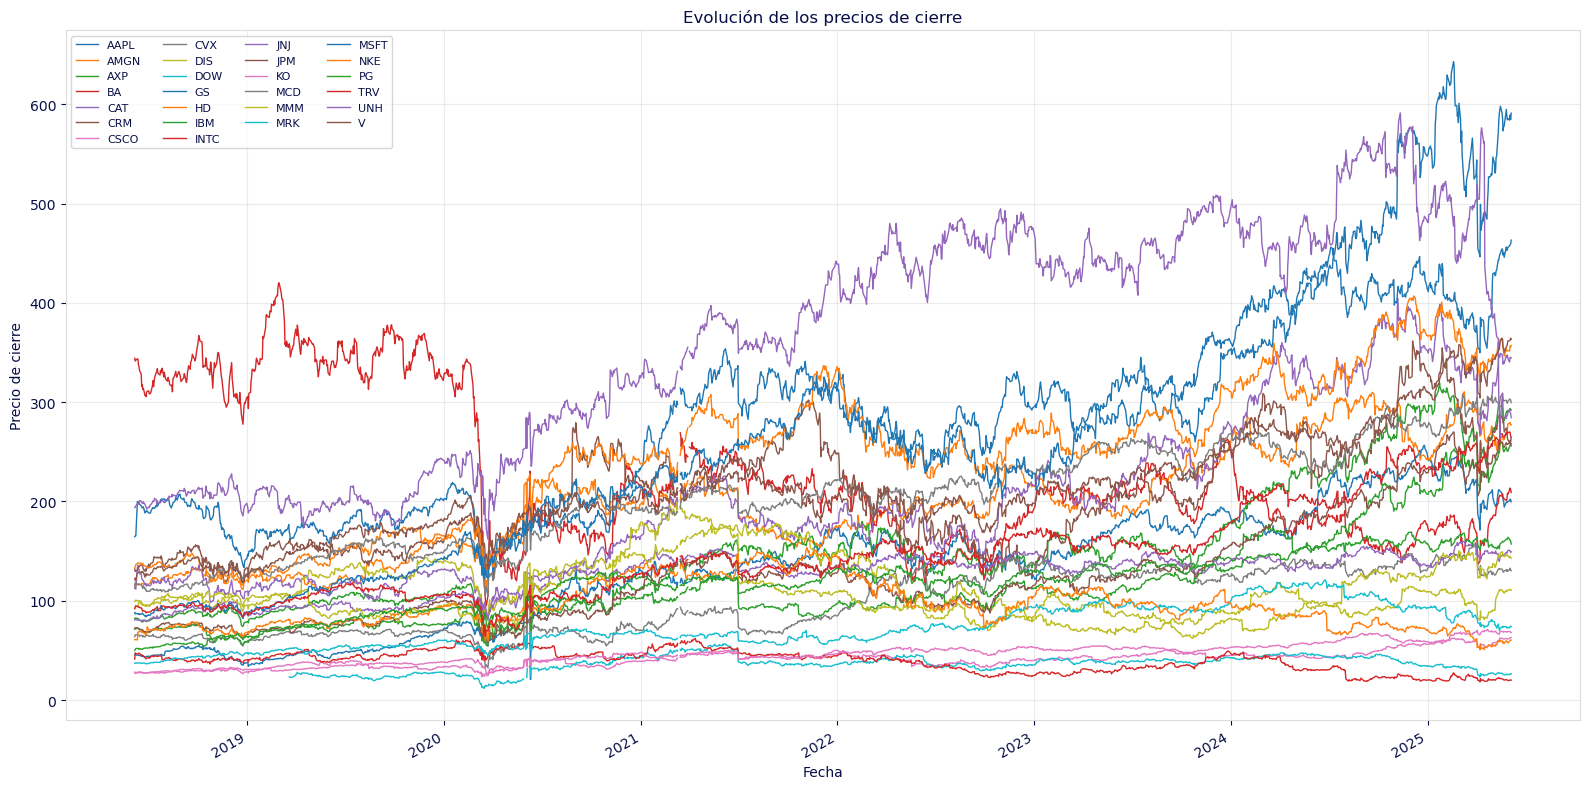

In [11]:
ax = close.plot(figsize=(16, 8), linewidth=1)
ax.set_title("Evolución de los precios de cierre")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio de cierre")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 10. Precios normalizados

La comparación de precios absolutos puede resultar poco clara cuando cada acción cotiza en una escala distinta. Para facilitar la comparación se normaliza cada serie tomando como base 100 su primera observación. Un valor de 120 indica que el precio se sitúa un 20 % por encima del valor inicial del periodo.

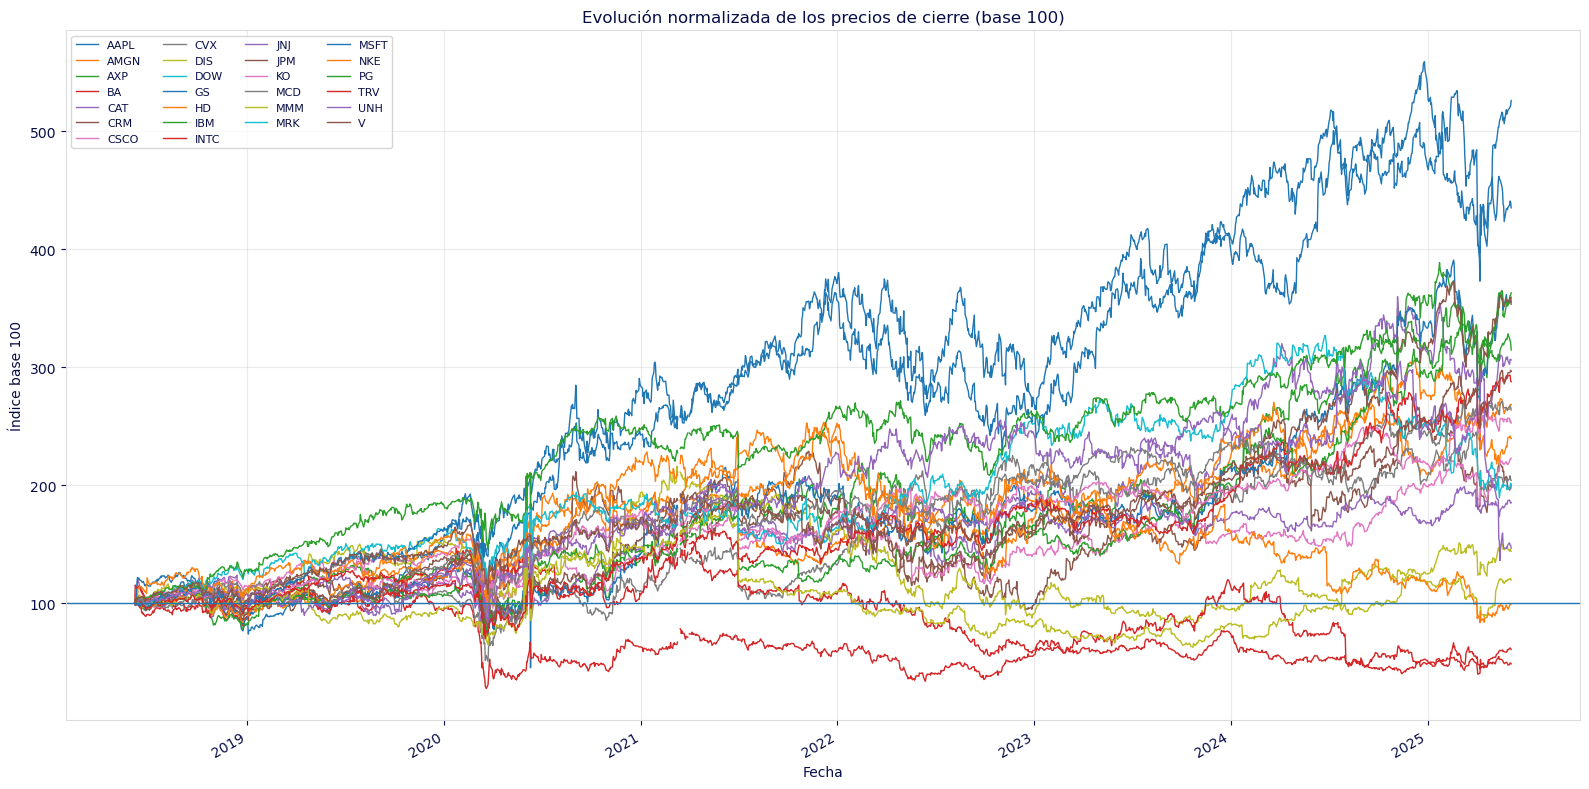

In [12]:
close_normalizado = close.divide(close.iloc[0]).multiply(100)

ax = close_normalizado.plot(figsize=(16, 8), linewidth=1)
ax.set_title("Evolución normalizada de los precios de cierre (base 100)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice base 100")
ax.axhline(100, linewidth=1)
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 11. Cálculo de rentabilidades

Se calculan las rentabilidades simples y logarítmicas a partir de los precios de cierre. Las rentabilidades permiten comparar empresas con precios de cotización distintos y constituyen una base más adecuada para estudiar dispersión, correlaciones y riesgo.

In [ ]:
returns = close.pct_change(fill_method=None)
log_returns = np.log(close / close.shift(1))

print("Rentabilidades simples:")
display(returns.head())

print("\nRentabilidades logarítmicas:")
display(log_returns.head())

## 12. Estadística descriptiva de las rentabilidades

Además de media, desviación típica y cuantiles, se calculan asimetría y curtosis. Estas dos medidas permiten describir desviaciones respecto de una distribución simétrica y detectar la presencia de colas pronunciadas.

In [ ]:
resumen_returns = returns.describe().T
resumen_returns["asimetria"] = returns.skew()
resumen_returns["curtosis"] = returns.kurtosis()
resumen_returns.index.name = "Ticker"

display(resumen_returns)

## 13. Distribución de las rentabilidades diarias

Los histogramas muestran la forma de la distribución de las rentabilidades de cada empresa. Las observaciones alejadas de la zona central permiten apreciar la presencia de movimientos diarios poco frecuentes.

In [ ]:
for ticker in orden:
    datos = returns[ticker].dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(datos, bins=40, alpha=0.85)
    plt.axvline(datos.mean(), linestyle="--", linewidth=1)
    plt.title(f"Distribución de las rentabilidades diarias - {ticker}")
    plt.xlabel("Rentabilidad diaria")
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

## 14. Comparación de las rentabilidades mediante diagramas de caja

El diagrama de caja permite comparar la dispersión de las rentabilidades y localizar visualmente observaciones extremas. La escala común facilita detectar qué empresas presentan movimientos diarios más amplios.

In [ ]:
plt.figure(figsize=(16, 7))
returns.boxplot(rot=90, showfliers=True)
plt.title("Distribución de las rentabilidades diarias por empresa")
plt.xlabel("Ticker")
plt.ylabel("Rentabilidad diaria")
plt.tight_layout()
plt.show()

## 15. Rentabilidad acumulada

La rentabilidad acumulada representa la evolución de una inversión teórica realizada al comienzo del periodo. El cálculo no incorpora dividendos, comisiones, impuestos ni otros costes de transacción.

In [ ]:
rentabilidad_acumulada = (1 + returns.fillna(0)).cumprod() - 1

ax = rentabilidad_acumulada.plot(figsize=(16, 8), linewidth=1)
ax.set_title("Rentabilidad acumulada")
ax.set_xlabel("Fecha")
ax.set_ylabel("Rentabilidad acumulada")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
rentabilidad_total = (close.iloc[-1] / close.iloc[0] - 1).sort_values(ascending=False)

tabla_rentabilidad_total = pd.DataFrame({
    "rentabilidad_total": rentabilidad_total,
    "rentabilidad_total_%": rentabilidad_total * 100
})

display(tabla_rentabilidad_total)

## 16. Volatilidad

La volatilidad se aproxima mediante la desviación típica de las rentabilidades. Para datos diarios se presenta también una estimación anualizada utilizando 252 sesiones bursátiles al año.

In [ ]:
media_diaria = returns.mean()
volatilidad_diaria = returns.std()

rentabilidad_media_anualizada = media_diaria * 252
volatilidad_anualizada = volatilidad_diaria * np.sqrt(252)

tabla_riesgo = pd.DataFrame({
    "rentabilidad_media_diaria": media_diaria,
    "volatilidad_diaria": volatilidad_diaria,
    "rentabilidad_media_anualizada_aprox": rentabilidad_media_anualizada,
    "volatilidad_anualizada": volatilidad_anualizada
}).sort_values("volatilidad_anualizada")

display(tabla_riesgo)

In [ ]:
volatilidad_anualizada.sort_values().plot(kind="bar", figsize=(14, 6))
plt.title("Volatilidad anualizada por empresa")
plt.xlabel("Ticker")
plt.ylabel("Volatilidad anualizada")
plt.tight_layout()
plt.show()

## 17. Relación entre rentabilidad media y volatilidad

El siguiente gráfico sitúa cada empresa según su rentabilidad media anualizada aproximada y su volatilidad anualizada. Su finalidad es descriptiva: permite comparar el comportamiento histórico observado durante el periodo disponible.

In [ ]:
plt.figure(figsize=(12, 8))
plt.scatter(volatilidad_anualizada, rentabilidad_media_anualizada, s=45)

for ticker in orden:
    x = volatilidad_anualizada[ticker]
    y = rentabilidad_media_anualizada[ticker]
    plt.annotate(ticker, (x, y), xytext=(4, 4), textcoords="offset points")

plt.axhline(0, linewidth=1)
plt.xlabel("Volatilidad anualizada")
plt.ylabel("Rentabilidad media anualizada aproximada")
plt.title("Rentabilidad media y volatilidad")
plt.tight_layout()
plt.show()

## 18. Correlación entre las rentabilidades

La correlación se calcula sobre rentabilidades y no sobre precios. De esta forma se analiza hasta qué punto los movimientos diarios de dos acciones tienden a producirse en la misma dirección. Valores próximos a 1 indican una asociación lineal positiva elevada, mientras que valores próximos a 0 reflejan una relación lineal débil.

In [ ]:
corr_returns = returns.corr()
display(corr_returns.round(3))

In [ ]:
plt.figure(figsize=(13, 11))
imagen = plt.imshow(corr_returns, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(imagen, label="Correlación")
plt.xticks(range(len(corr_returns.columns)), corr_returns.columns, rotation=90)
plt.yticks(range(len(corr_returns.index)), corr_returns.index)
plt.title("Matriz de correlación de las rentabilidades diarias")
plt.tight_layout()
plt.show()

In [ ]:
pares = (
    corr_returns.where(
        np.triu(np.ones(corr_returns.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(ascending=False)
)

print("Diez pares con mayor correlación:")
display(pares.head(10).to_frame("correlacion"))

print("\nDiez pares con menor correlación:")
display(pares.tail(10).to_frame("correlacion"))

## 19. Rango intradía

El rango intradía se obtiene a partir de la diferencia entre el máximo y el mínimo de cada sesión. Para hacer comparables las empresas se expresa como proporción del precio mínimo diario.

In [ ]:
rango_intradía = (high - low) / low

resumen_rango = pd.DataFrame({
    "media": rango_intradía.mean(),
    "mediana": rango_intradía.median(),
    "maximo": rango_intradía.max()
}).sort_values("media", ascending=False)

display(resumen_rango)

In [ ]:
rango_intradía.mean().sort_values().plot(kind="bar", figsize=(14, 6))
plt.title("Rango intradía medio relativo")
plt.xlabel("Ticker")
plt.ylabel("(High - Low) / Low")
plt.tight_layout()
plt.show()

## 20. Rentabilidad intradía

La rentabilidad intradía mide la variación entre apertura y cierre de una misma sesión. Este cálculo separa el movimiento producido durante el horario de negociación del cambio ocurrido entre el cierre previo y la apertura siguiente.

In [ ]:
intraday_return = (close - open_) / open_

resumen_intraday = pd.DataFrame({
    "media": intraday_return.mean(),
    "desviacion": intraday_return.std(),
    "minimo": intraday_return.min(),
    "maximo": intraday_return.max()
}).sort_values("desviacion", ascending=False)

display(resumen_intraday)

## 21. Gaps de apertura

El *gap* de apertura compara el precio de apertura de una sesión con el cierre de la sesión anterior. Un valor positivo indica una apertura por encima del cierre previo; un valor negativo indica lo contrario.

In [ ]:
gap_apertura = open_ / close.shift(1) - 1

resumen_gap = pd.DataFrame({
    "media": gap_apertura.mean(),
    "desviacion": gap_apertura.std(),
    "minimo": gap_apertura.min(),
    "maximo": gap_apertura.max()
}).sort_values("desviacion", ascending=False)

display(resumen_gap)

In [ ]:
gap_apertura.abs().mean().sort_values().plot(kind="bar", figsize=(14, 6))
plt.title("Magnitud media absoluta del gap de apertura")
plt.xlabel("Ticker")
plt.ylabel("Gap absoluto medio")
plt.tight_layout()
plt.show()

## 22. Evolución del volumen negociado

El volumen se analiza mediante su evolución temporal y mediante una media móvil de 20 sesiones. La media móvil suaviza las oscilaciones diarias y facilita la identificación de periodos con actividad persistentemente elevada o reducida.

In [ ]:
volume_normalizado = volume.divide(volume.iloc[0]).multiply(100)

ax = volume_normalizado.plot(figsize=(16, 8), linewidth=0.9)
ax.set_title("Evolución normalizada del volumen (base 100)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice base 100")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
volume_ma20 = volume.rolling(20).mean()

for ticker in orden:
    plt.figure(figsize=(12, 5))
    plt.plot(volume[ticker], label="Volumen", linewidth=0.8)
    plt.plot(volume_ma20[ticker], label="Media móvil 20 sesiones", linewidth=1.2)
    plt.title(f"Volumen negociado - {ticker}")
    plt.xlabel("Fecha")
    plt.ylabel("Volumen")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 23. Relación entre volumen y magnitud del movimiento del precio

Se calcula la correlación entre el volumen y el valor absoluto de la rentabilidad diaria. Esta medida permite comprobar si las sesiones con mayor actividad tienden a coincidir con movimientos de precio más intensos, con independencia de que dichos movimientos sean positivos o negativos.

In [ ]:
corr_vol_mov = pd.Series(index=orden, dtype=float)

for ticker in orden:
    datos = pd.concat(
        [volume[ticker], returns[ticker].abs()],
        axis=1
    ).dropna()
    datos.columns = ["volume", "abs_return"]
    corr_vol_mov[ticker] = datos["volume"].corr(datos["abs_return"])

corr_vol_mov = corr_vol_mov.sort_values(ascending=False)

display(corr_vol_mov.to_frame("corr_volumen_abs_rentabilidad"))

In [ ]:
corr_vol_mov.sort_values().plot(kind="bar", figsize=(14, 6))
plt.title("Correlación entre volumen y magnitud de la rentabilidad diaria")
plt.xlabel("Ticker")
plt.ylabel("Correlación")
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

## 24. Medias móviles de precios

Las medias móviles de 20 y 50 sesiones se utilizan para suavizar la serie de precios y observar cambios de tendencia con menor influencia del ruido diario. Se representan por separado para cada empresa para evitar superponer demasiadas series en una sola figura.

In [ ]:
ma20 = close.rolling(20).mean()
ma50 = close.rolling(50).mean()

for ticker in orden:
    plt.figure(figsize=(12, 5))
    plt.plot(close[ticker], label="Cierre", linewidth=1)
    plt.plot(ma20[ticker], label="Media móvil 20", linewidth=1)
    plt.plot(ma50[ticker], label="Media móvil 50", linewidth=1)
    plt.title(f"Precio de cierre y medias móviles - {ticker}")
    plt.xlabel("Fecha")
    plt.ylabel("Precio")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 25. Volatilidad móvil

La volatilidad no suele permanecer constante a lo largo del tiempo. Para observar su evolución se calcula una desviación típica móvil de 30 sesiones y se anualiza mediante el factor correspondiente a 252 sesiones bursátiles.

In [ ]:
rolling_vol_30 = returns.rolling(30).std() * np.sqrt(252)

ax = rolling_vol_30.plot(figsize=(16, 8), linewidth=0.9)
ax.set_title("Volatilidad móvil anualizada de 30 sesiones")
ax.set_xlabel("Fecha")
ax.set_ylabel("Volatilidad anualizada")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 26. Drawdown

El *drawdown* mide la caída de una serie respecto de su máximo histórico previo dentro del periodo analizado. Esta medida complementa la volatilidad porque refleja directamente la magnitud de las pérdidas sufridas desde un máximo anterior.

In [ ]:
maximo_acumulado = close.cummax()
drawdown = close / maximo_acumulado - 1

max_drawdown = drawdown.min().sort_values()

tabla_drawdown = pd.DataFrame({
    "max_drawdown": max_drawdown,
    "max_drawdown_%": max_drawdown * 100
})

display(tabla_drawdown)

In [ ]:
ax = drawdown.plot(figsize=(16, 8), linewidth=0.9)
ax.set_title("Drawdown a lo largo del periodo")
ax.set_xlabel("Fecha")
ax.set_ylabel("Drawdown")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
max_drawdown.sort_values().plot(kind="bar", figsize=(14, 6))
plt.title("Máximo drawdown observado por empresa")
plt.xlabel("Ticker")
plt.ylabel("Máximo drawdown")
plt.tight_layout()
plt.show()

## 27. Sesiones con mayores movimientos

Se identifican para cada empresa las cinco mayores subidas y las cinco mayores caídas diarias. Esta revisión permite localizar fechas que merecen un análisis posterior y comprobar si determinados episodios extremos afectan simultáneamente a varias empresas.

In [ ]:
extremos = {}

for ticker in orden:
    serie = returns[ticker].dropna()
    extremos[ticker] = {
        "mayores_subidas": serie.nlargest(5),
        "mayores_caidas": serie.nsmallest(5)
    }

for ticker in orden:
    print("=" * 70)
    print(ticker)
    print("\nMayores subidas:")
    display(extremos[ticker]["mayores_subidas"].to_frame("rentabilidad"))
    print("Mayores caídas:")
    display(extremos[ticker]["mayores_caidas"].to_frame("rentabilidad"))

## 28. Detección descriptiva de valores extremos mediante IQR

Como complemento se aplica la regla del rango intercuartílico a las rentabilidades. Una observación se considera extrema cuando queda por debajo de `Q1 - 1.5·IQR` o por encima de `Q3 + 1.5·IQR`. Este criterio se utiliza únicamente para describir la frecuencia de movimientos alejados del centro de la distribución; no implica que las observaciones sean erróneas.

In [ ]:
outliers_iqr = {}

for ticker in orden:
    serie = returns[ticker].dropna()
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    mascara = (serie < limite_inf) | (serie > limite_sup)

    outliers_iqr[ticker] = {
        "n_outliers": int(mascara.sum()),
        "porcentaje": 100 * mascara.mean(),
        "limite_inferior": limite_inf,
        "limite_superior": limite_sup
    }

tabla_outliers = pd.DataFrame(outliers_iqr).T.sort_values(
    "porcentaje",
    ascending=False
)

display(tabla_outliers)

In [ ]:
tabla_outliers["porcentaje"].sort_values().plot(kind="bar", figsize=(14, 6))
plt.title("Porcentaje de rentabilidades extremas según el criterio IQR")
plt.xlabel("Ticker")
plt.ylabel("Porcentaje de observaciones")
plt.tight_layout()
plt.show()

## 29. Evolución anual

Cuando el periodo contiene varios años, una agregación anual permite comparar el comportamiento de cada empresa en intervalos homogéneos. La rentabilidad anual se obtiene a partir de los precios de cierre de final de año.

In [ ]:
if isinstance(close.index, pd.DatetimeIndex):
    close_fin_ano = close.resample("YE").last()
    rentabilidad_anual = close_fin_ano.pct_change(fill_method=None)

    print("Rentabilidades por año:")
    display(rentabilidad_anual)

    plt.figure(figsize=(16, 8))
    imagen = plt.imshow(rentabilidad_anual.T, aspect="auto")
    plt.colorbar(imagen, label="Rentabilidad")
    plt.xticks(
        range(len(rentabilidad_anual.index)),
        [fecha.year for fecha in rentabilidad_anual.index],
        rotation=45
    )
    plt.yticks(range(len(rentabilidad_anual.columns)), rentabilidad_anual.columns)
    plt.title("Rentabilidades anuales por empresa")
    plt.xlabel("Año")
    plt.ylabel("Ticker")
    plt.tight_layout()
    plt.show()
else:
    print(
        "El índice no es de tipo DatetimeIndex. "
        "No se realiza la agregación anual."
    )

## 30. Tabla resumen del análisis

Se reúnen varias métricas en una única tabla para disponer de una visión compacta del comportamiento de cada empresa durante el periodo analizado. Las medidas anualizadas suponen que los datos tienen frecuencia diaria y utilizan 252 sesiones bursátiles por año.

In [ ]:
tabla_resumen = pd.DataFrame(index=orden)

tabla_resumen["precio_inicial"] = close.iloc[0]
tabla_resumen["precio_final"] = close.iloc[-1]
tabla_resumen["rentabilidad_total"] = close.iloc[-1] / close.iloc[0] - 1
tabla_resumen["rentabilidad_media_diaria"] = returns.mean()
tabla_resumen["volatilidad_diaria"] = returns.std()
tabla_resumen["rentabilidad_media_anualizada_aprox"] = returns.mean() * 252
tabla_resumen["volatilidad_anualizada"] = returns.std() * np.sqrt(252)
tabla_resumen["max_drawdown"] = drawdown.min()
tabla_resumen["rango_intradía_medio"] = rango_intradía.mean()
tabla_resumen["gap_abs_medio"] = gap_apertura.abs().mean()
tabla_resumen["volumen_medio"] = volume.mean()
tabla_resumen["corr_volumen_abs_return"] = corr_vol_mov

display(tabla_resumen)

## 31. Observaciones finales

El análisis exploratorio permite caracterizar el comportamiento histórico de las empresas desde varias perspectivas. Los precios normalizados facilitan la comparación de trayectorias; las rentabilidades permiten estudiar variación y dependencia; la volatilidad y el *drawdown* describen dimensiones distintas del riesgo observado; y las variables intradía, los *gaps* y el volumen aportan información adicional sobre la dinámica de cada acción.

Las correlaciones calculadas muestran relaciones contemporáneas dentro del periodo disponible, pero no establecen causalidad. Del mismo modo, las rentabilidades y volatilidades históricas no constituyen por sí mismas una estimación de resultados futuros.

A partir de este punto pueden plantearse análisis posteriores, como agrupación de empresas según comportamiento, reducción de dimensionalidad, estudio de regímenes de volatilidad, modelos de series temporales o construcción de variables para modelos predictivos.